# Quasar spectra and bandpass photometry

This notebook combines a physical, variable full-Kerr disk continuum with an empirical quasar spectrum and integrates the result through the bundled Rubin LSST response curves. The empirical model adds broad and narrow emission-line templates, dust and intergalactic attenuation, host-galaxy light, and optional seeded population scatter. The physical disk still supplies the continuum at each wavelength, with its own microlensing magnification.

The physical continuum uses 32 wavelength nodes by default. A same-map check against 64 nodes found sub-millimagnitude differences in five LSST bands, 1.8 mmag in $u$, and a 0.47 mmag 95th-percentile difference in the retained microlensed spectrum for a representative Q2237 image-B map. Use 64 nodes when that extra accuracy is more important than throughput. The dense returned spectrum is interpolated from these physical channels and therefore does not create a spatial disk image at every displayed wavelength.

GIF previews are embedded below. If needed, only their duration is shortened,
keeping the original resolution, cadence, and playback speed. The full GIFs
are generated by this notebook and linked below each animation.


In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import torch
from IPython.display import Image, display
from matplotlib import pyplot as plt

import microcaustics as mc
import microcaustics.plotting as mcp

plt.rcParams.update(mcp.publication_style())
OUTPUT = Path("quasar_spectra_output")
OUTPUT.mkdir(exist_ok=True)

capabilities = mc.RuntimeCapabilities.detect()
use_cuda = capabilities.cuda_available and capabilities.triton_importable
runtime = mc.RuntimeConfig(
    device="cuda" if use_cuda else "cpu",
    backend="triton" if use_cuda else "torch-eager",
    strict_backend=use_cuda, dtype=torch.float32, memory_fraction=0.95,
)
duration_days = 3650.0
times_days = torch.arange(0.0, duration_days + 1.0, 1.0)
source_pixels = 512 if use_cuda else 128
wavelength_samples = 32  # use 64 for the higher-accuracy option
wavelength_batch_size = 16
spectrum_wavelengths = np.linspace(3250.0, 10900.0, 800)
print(mcp.runtime_description())

GIF_DIRECTORY = Path("../assets/animations")
GIF_DIRECTORY.mkdir(parents=True, exist_ok=True)


Python 3.11.15 | PyTorch 2.12.1+cu130 | Windows AMD64 | CUDA 13.0, NVIDIA GeForce RTX 5070 Ti, compute capability 12.0


In [2]:
driver = mc.broken_power_law_driving_signal(
    cadence_days=1.0, max_duration_days=duration_days, history_days=1000.0,
    break_timescale_days=200.0, alpha_L=1.0, alpha_R=3.0,
    standard_deviation=0.10, seed=11,
)
disk = mc.KerrDiskModel(
    black_hole_mass_solar=10.0**9.08, eddington_ratio=0.34,
    bands_angstrom={"reference": 6000.0},
    spin=0.74, inclination_deg=10.0, position_angle_deg=0.0,
    lamp_fraction=0.1, corona_height_above_isco_rg=20.0,
    driving_signal=driver, source_grid_shape=source_pixels,
    enclosed_flux_fraction=0.999, source_margin=1.05,
    compile_solver=use_cuda,
)
system = mc.MicrolensingSystem(
    macro=mc.MacroLens(0.391, 0.391, shear_angle_deg=141.73),
    lens_redshift=0.0395, source_redshift=1.695, source=disk,
    stars=mc.PointMassField([0.0], [0.0], [0.3]), runtime=runtime,
)
# Disable optional band-only scatter so the displayed spectrum and its
# integrated photometry can be compared directly.
spectrum_model = mc.QuasarSpectrumPopulation(
    band_magnitude_scatter=0.0, amplitude_color_scatter=0.0,
    amplitude_band_scatter=0.0,
).sample(seed=2026)

if use_cuda:
    torch.cuda.synchronize()
started = perf_counter()
curve = system.source_light_curve(
    times_days, bandpasses="lsst", spectral_model=spectrum_model,
    wavelength_samples=wavelength_samples,
    wavelength_batch_size=wavelength_batch_size,
    include_microlensing_only=True, return_spectrum=True,
    spectrum_wavelengths=spectrum_wavelengths,
)
if use_cuda:
    torch.cuda.synchronize()
elapsed = perf_counter() - started
assert curve.band_names == tuple("ugrizy")
assert curve.spectrum.total_flux.shape == (len(times_days), len(spectrum_wavelengths))
print(f"Generated {len(times_days)} daily spectra and six-band epochs in {elapsed:.2f} s")
print("Spectrum population seed:", spectrum_model.population_seed)
print("Bandpass release:", curve.metadata["bandpasses"]["version"])


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\primary.py:223: CompilationWarning: Compilation event 1: preparing a new torch.compile specialization for primary Kerr ray tracing on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  calculation, execution = _primary_calculation(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\coordinates.py:1158: CompilationWarning: Compilation event 2: preparing a new torch.compile specialization for Kerr observer coordinates on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  solver, execution = _coordinate_solver(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\lamppost.py:625: CompilationWarning: Compilation event 3: preparing a new torch.compile specialization for axis-lamppost ray tracing on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  rays = trace_axis_lamppost(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\reprocessing.py:553: CompilationWarning: Compilation event 4: preparing a new torch.compile specialization for retarded thermal driving on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  temperature4, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:209: CompilationWarning: Compilation event 5: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_thermal_flux(left, right, fraction, arguments, runtime)


Generated 3651 daily spectra and six-band epochs in 15.10 s
Spectrum population seed: 2026
Bandpass release: lsst2023 / throughputs tag 1.9


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:209: CompilationWarning: Compilation event 6: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_thermal_flux(left, right, fraction, arguments, runtime)


## One observed spectrum and its six-band light curves

The continuum is time dependent. Emission-line and host templates set the mean spectral energy distribution and are added without pretending that the compact continuum disk spatially represents the broad-line region or host galaxy. For a lensed calculation, the default `host_lensing="omit"` excludes host light. Source-only photometry retains it.

The faint colored shapes behind each spectrum show the bundled LSST throughput curves on an independent dimensionless scale, as in [Figure 2 of Fagin et al. (2025)](https://doi.org/10.3847/1538-4357/addabc).


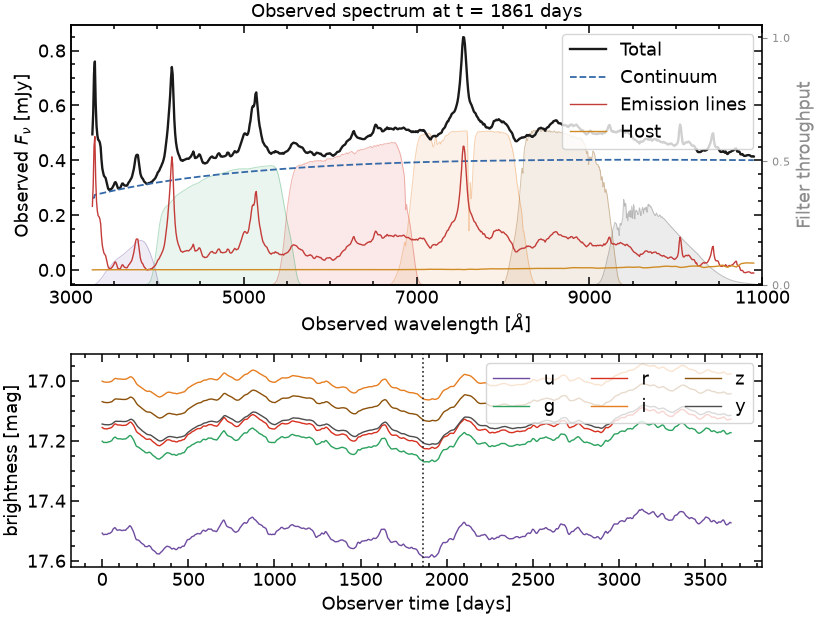

In [3]:
spectrum = curve.spectrum
wavelength = spectrum.wavelengths_angstrom.detach().cpu().numpy()
total = spectrum.total_flux.detach().cpu().numpy()
continuum = spectrum.continuum_flux.detach().cpu().numpy()
line_flux = spectrum.components["emission_lines"].detach().cpu().numpy()
host_flux = spectrum.components["host"].detach().cpu().numpy()
epoch = int(torch.argmax(torch.std(curve.magnitude, dim=1)))
colors = mcp.band_colors(curve.band_names)

figure, (spectrum_axis, curve_axis) = plt.subplots(
    2, 1, figsize=(8.5, 6.5), gridspec_kw={"height_ratios": (1.0, 0.82)},
)
spectrum_axis.plot(wavelength, 1e3 * total[epoch], color="0.1", lw=1.7, label="Total")
spectrum_axis.plot(wavelength, 1e3 * continuum[epoch], color="#3569a8", ls="--", lw=1.3, label="Continuum")
spectrum_axis.plot(wavelength, 1e3 * line_flux[epoch], color="#c43c39", lw=1.0, label="Emission lines")
spectrum_axis.plot(wavelength, 1e3 * host_flux[epoch], color="#d08c24", lw=1.0, label="Host")
spectrum_axis.set(xlim=(3000, 11000), xlabel=r"Observed wavelength [$\AA$]", ylabel=r"Observed $F_\nu$ [mJy]", title=f"Observed spectrum at t = {float(curve.times_days[epoch]):.0f} days")
spectrum_axis.set_xticks([3000, 5000, 7000, 9000, 11000])
mcp.plot_bandpass_background(spectrum_axis, "lsst")
spectrum_axis.legend(loc="upper right", frameon=True)
mcp.finish_axis(spectrum_axis)
for band_index, band in enumerate(curve.band_names):
    curve_axis.plot(curve.times_days.cpu(), curve.magnitude[:, band_index].cpu(), color=colors[band], lw=1.0, label=band)
curve_axis.axvline(float(curve.times_days[epoch]), color="0.15", ls=":", lw=1.2)
curve_axis.invert_yaxis()
curve_axis.set(xlabel="Observer time [days]", ylabel="brightness [mag]")
curve_axis.legend(loc="upper right", ncol=3, frameon=True)
mcp.finish_axis(curve_axis)
figure.tight_layout()
figure.savefig(OUTPUT / "quasar_spectrum_and_lsst_photometry.pdf", bbox_inches="tight")
plt.show()


## Custom response curves

Pass `bandpasses="lsst"` for the bundled filters or construct a `BandpassSet` from arbitrary observed-frame response curves. The same call returns integrated photometry, component fluxes, the mean-driver comparison, and the optional spectrum without repeating the source calculation.


In [4]:
custom_bandpasses = mc.BandpassSet((
    mc.Bandpass([4000, 4500, 5200, 5700], [0, 1, 1, 0], "blue"),
    mc.Bandpass([7000, 7600, 8500, 9100], [0, 1, 1, 0], "red"),
))
custom_curve = system.source_light_curve(
    times_days[:2], bandpasses=custom_bandpasses, spectral_model=spectrum_model,
    wavelength_samples=32, wavelength_batch_size=16,
)
print("Custom bands:", custom_curve.band_names)
print("Custom magnitudes at day zero:", custom_curve.magnitude[0].cpu().numpy())


Custom bands: ('blue', 'red')
Custom magnitudes at day zero: [17.20192  17.007175]


## Evolving observed spectrum

The GIF uses the spectrum already retained by the light-curve call. It does not rerun the disk or photometry. The upper panel evolves the full observed spectrum and continuum. The lower panel shows the synchronized six-band magnitudes with the current epoch marked.



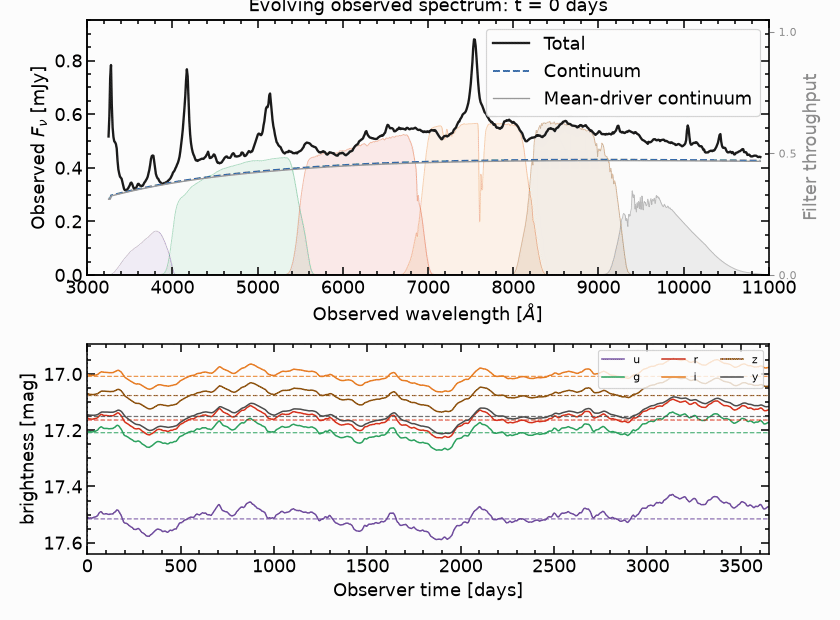

In [5]:
gif_path = mcp.animate_spectrum_and_photometry(
    curve, GIF_DIRECTORY / "evolving_quasar_spectrum.gif",
    max_frames=48, fps=8.0, wavelength_limits=(3000.0, 11000.0),
    bandpasses="lsst",
)
display(mcp.gif_preview(gif_path))
print("Wrote", gif_path)


[View the full GIF](../assets/animations/evolving_quasar_spectrum.gif)

## Q2237 image B: a simulated caustic crossing

We now use Q2237+0305 image B's full moving Salpeter stellar field with stellar seed 11 and the same source and plotting conventions as notebook 03. The disk stays fixed. Production IPM uses $10^7$ rays, $1024^2$ magnification maps, 25-day map epochs and daily intrinsic photometry. Caustic labels identify the crossings in this realization.

Only the continuum varies and is microlensed. The emission-line template is normalized to the mean intrinsic continuum and receives the macro magnification only. Host light is omitted from this compact lensed-source example. The spectrum includes intrinsic dust reddening and approximate mean intergalactic H I absorption (the Lyman forest and limit). These are static attenuation factors. This example does not model broad-line reverberation or individual intervening absorbers.


In [6]:
from dataclasses import replace
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Establish the same physical source support as notebook 03 before selecting
# sparse continuum channels. Changing the spectral sampling then keeps this
# realization's star field and source geometry fixed.
support_disk = replace(
    disk, bands_angstrom={"blue": 3000.0, "red": 11000.0},
    wavelengths_angstrom=(), band_names=(),
    lamppost_nalpha=1024, lamppost_radial_bins=512,
)
population = mc.StellarPopulation.salpeter(
    mean_mass_solar=0.3, mass_ratio=100.0,
    kinematics=mc.SkyProjectedKinematics(
        ra_deg=340.126125, dec_deg=3.358611,
        stellar_dispersion_km_s=170.0,
        peculiar_velocity_dispersion_km_s=235.0,
        include_cmb_dipole=True, seed=0,
    ),
)
lensed_system = mc.MicrolensingSystem(
    macro=mc.MacroLens(0.391, 0.391, shear_angle_deg=141.73),
    lens_redshift=0.0395, source_redshift=1.695, source=support_disk,
    stellar_population=population, map_grid_shape=1024,
    caustic_grid_shape=8192, duration_days=duration_days,
    light_loss=0.01, safety_scale=1.5, seed=11, runtime=runtime,
)
realization = lensed_system.realize()
lensed_system = lensed_system.with_source(realization.source)
source_grid = realization.source_grid
map_times = torch.arange(0.0, duration_days + 12.5, 25.0)
method = mc.production_ipm_config(rays=10_000_000)
schedule = mc.production_dynamic_config(temporal_batch_size=30)
caustics = mc.CausticConfig(
    far_field_approx=method.far_field_approx, temporal_batch_size=10,
)
captured_caustics = []
def capture_caustics(index, frame):
    field = frame.caustics.caustics
    segments = field.caustic_segments_uas
    if field.invalid_segment_mask is not None:
        segments = segments[~field.invalid_segment_mask]
    captured_caustics.append(segments.detach().cpu().numpy())

print("Stars:", len(realization.stars), flush=True)
started = perf_counter()
lensed_curve = lensed_system.light_curve(
    map_times, flux_times_days=times_days,
    bandpasses="lsst", spectral_model=spectrum_model,
    wavelength_samples=wavelength_samples,
    wavelength_batch_size=wavelength_batch_size,
    return_spectrum=True, spectrum_wavelengths=spectrum_wavelengths,
    include_labels=True, include_microlensing_only=True,
    method=method, schedule=schedule, caustics=caustics,
    keep_maps_at_days=map_times, map_observer=capture_caustics,
)
crossing_times = lensed_curve.labels.times_days[lensed_curve.labels.crossing_events]
print("Source-center crossing epochs [days]:", crossing_times.tolist(), flush=True)
print(f"Lensed calculation: {perf_counter() - started:.1f} s", flush=True)
assert len(crossing_times) > 0, "Inspect another seed to select a real crossing"
assert torch.all(lensed_curve.times_days.diff() == 1)
assert len(lensed_curve.maps) == len(map_times) == len(captured_caustics)
for name in ("emission_lines", "host"):
    component = lensed_curve.spectrum.components[name]
    assert torch.equal(component, component[:1].expand_as(component))
assert torch.count_nonzero(lensed_curve.spectrum.components["host"]) == 0


Stars: 3936


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:163: CompilationWarning: Compilation event 7: preparing a new torch.compile specialization for relativistic disk brightness on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  brightness, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 8: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:902: CompilationWarning: Compilation event 9: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(
C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1291: CompilationWarning: Compilation event 10: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:209: CompilationWarning: Compilation event 11: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_thermal_flux(left, right, fraction, arguments, runtime)


Source-center crossing epochs [days]: [1300.0]


Lensed calculation: 2.5 s


## Magnification map, spectrum, and light-curve animation

The upper-left panel shows the evolving magnification map, caustics and true non-circular 95%-flux disk isophotes at 3000, 5000, 7000, 9000 and 11000 Angstrom. The upper-right panel adds the full empirical spectrum to the lensed and unlensed continua. The separate middle-right panel shows continuum magnification. The lower panel shows all six response-integrated LSST light curves, with solid lines for microlensing plus variability and dashed lines for microlensing only. The vertical marker follows each 25-day map through the daily light curves.

Running the notebook writes the full ten-year GIF. The embedded preview shows
days 400–2600 around the sampled caustic crossing at day 1300.


In [7]:
contour_wavelengths = np.array([3000., 5000., 7000., 9000., 11000.])
contour_colors = ("#5e4fa2", "#3288bd", "#66c2a5", "#fdae61", "#d53e4f")
contour_source = realization.source.with_bands({
    str(int(wave)): float(wave) for wave in contour_wavelengths
})
resolved_runtime = mc.resolve_runtime(runtime)
contour_summary = mcp.mean_source_isophotes(
    contour_source, times_days, source_grid, fraction=0.95, batch_size=8,
    dtype=resolved_runtime.dtype, device=resolved_runtime.device,
)
contour_images = contour_summary.images
contour_levels = contour_summary.levels
contour_r95_uas = contour_summary.area_equivalent_radii_uas
source_x, source_y = contour_summary.x_uas, contour_summary.y_uas
sx0, sx1, sy0, sy1 = source_grid.bounds_uas
assert np.allclose(contour_summary.enclosed_fractions, 0.95, atol=0.002)

lsst_bands = dict.fromkeys(lensed_curve.band_names)
colors = mcp.band_colors(lensed_curve.band_names)
wavelengths = lensed_curve.spectrum.wavelengths_angstrom.cpu().numpy()
map_indices = np.searchsorted(times_days.numpy(), map_times.numpy())
observed = lensed_curve.spectrum
spectra = {
    "variable_unlensed": observed.unlensed_continuum_flux.cpu().numpy()[map_indices],
    "variable_lensed": observed.continuum_flux.cpu().numpy()[map_indices],
    "total_lensed": observed.total_flux.cpu().numpy()[map_indices],
    "mean_lensed": observed.microlensing_only_continuum_flux.cpu().numpy()[map_indices],
}
static_curve = replace(lensed_curve, flux=lensed_curve.microlensing_only_flux)
OUTPUT_DIRECTORY, FPS = OUTPUT, 8
def magnitude_numpy(flux):
    return mc.flux_to_magnitude(flux).detach().cpu().numpy()


In [8]:
def render_case(
    prefix, title, map_times, flux_times, maps, spectra,
    variable_curve, static_curve, *, caustics=None,
):
    map_times_np = map_times.detach().cpu().numpy()
    flux_times_np = flux_times.detach().cpu().numpy()
    log_maps = np.stack([
        torch.log10(item.values.clamp_min(1.0e-2)).detach().cpu().numpy()
        for item in maps
    ])
    finite_maps = log_maps[np.isfinite(log_maps)]
    map_limits = (
        float(np.nanpercentile(finite_maps, 0.2)),
        float(np.nanpercentile(finite_maps, 99.8)),
    )

    variable_lensed_mag = magnitude_numpy(variable_curve.flux.detach().cpu().numpy())
    static_lensed_mag_daily = magnitude_numpy(static_curve.flux.detach().cpu().numpy())
    map_indices = np.searchsorted(flux_times_np, map_times_np)
    static_lensed_mag = static_lensed_mag_daily[map_indices]

    band_handles = [
        Line2D([0], [0], color=colors[band], lw=1.8, label=band)
        for band in lsst_bands
    ]
    unlensed_spectra = spectra["variable_unlensed"]
    lensed_spectra = spectra["variable_lensed"]
    curve_times = flux_times_np
    lensed_mag = variable_lensed_mag
    baseline_mag = static_lensed_mag_daily
    suffix = "microlensing_and_variability"
    state_title = "Microlensing + intrinsic variability"
    light_curve_title = "Daily LSST bandpass photometry"

    flux_max = 1.08e3 * float(np.nanpercentile(
        np.concatenate((unlensed_spectra.ravel(), spectra["total_lensed"].ravel())), 99.95,
    ))
    ratios = lensed_spectra / np.clip(unlensed_spectra, 1.0e-30, None)
    ratio_limits = (
        max(0.0, 0.94 * float(np.nanpercentile(ratios, 0.1))),
        1.06 * float(np.nanpercentile(ratios, 99.9)),
    )
    combined_mag = (
        lensed_mag.ravel() if baseline_mag is None
        else np.concatenate((lensed_mag.ravel(), baseline_mag.ravel()))
    )
    mag_pad = max(0.05, 0.04 * float(np.ptp(combined_mag)))
    mag_limits = (
        float(np.nanmin(combined_mag) - mag_pad),
        float(np.nanmax(combined_mag) + mag_pad),
    )

    frames = []
    for frame_index, frame_time in enumerate(map_times_np):
        figure = plt.figure(figsize=(12.8, 8.35))
        grid = figure.add_gridspec(
            3, 2,
            width_ratios=(1.0, 1.25),
            height_ratios=(1.25, 0.48, 0.92),
            left=0.065, right=0.985, bottom=0.09, top=0.925,
            wspace=0.25, hspace=0.42,
        )
        map_axis = figure.add_subplot(grid[:2, 0])
        spectrum_axis = figure.add_subplot(grid[0, 1])
        ratio_axis = figure.add_subplot(grid[1, 1], sharex=spectrum_axis)
        light_curve_axis = figure.add_subplot(grid[2, :])

        map_artist = map_axis.imshow(
            log_maps[frame_index], origin="lower", extent=source_grid.bounds_uas,
            cmap="magma", vmin=map_limits[0], vmax=map_limits[1],
            interpolation="bilinear",
        )
        figure.colorbar(
            map_artist, ax=map_axis, fraction=0.046, pad=0.025,
            label=r"$\log_{10}\mu$",
        )
        if caustics is not None:
            map_axis.add_collection(LineCollection(
                caustics[frame_index], colors="#38d9ff", linewidths=0.75,
                alpha=0.90, zorder=5,
            ))
        for contour_image, contour_level, contour_color in zip(
            contour_images, contour_levels, contour_colors, strict=True,
        ):
            map_axis.contour(
                source_x, source_y, contour_image, levels=[contour_level],
                colors=[contour_color], linewidths=1.15, zorder=6,
            )
        map_axis.scatter([0.0], [0.0], marker="+", s=55, linewidths=1.2, color="white", zorder=7)
        contour_handles = [
            Line2D(
                [0], [0], color=color, lw=1.4,
                label=rf"{wave:.0f} Angstrom  $R_{{95}}={radius:.2f}\,\mu\mathrm{{as}}$",
            )
            for wave, radius, color in zip(
                contour_wavelengths, contour_r95_uas,
                contour_colors, strict=True,
            )
        ]
        map_axis.legend(
            handles=contour_handles, title="Mean 95% flux isophote",
            ncol=1, frameon=True, fontsize=6.5, title_fontsize=7,
            loc="upper left", borderpad=0.35, handlelength=1.6,
        )
        map_axis.set(xlim=(sx0, sx1), ylim=(sy0, sy1))
        map_axis.set_title("Moving microlenses; stationary Q2237 disk")
        mcp.add_scale_bar(map_axis, 1.0, label=r"1 $\mu$as", color="white")
        mcp.hide_image_axes(map_axis)

        unlensed = unlensed_spectra[frame_index]
        lensed = lensed_spectra[frame_index]
        spectrum_axis.plot(
            wavelengths, 1.0e3 * spectra["mean_lensed"][frame_index],
            color="0.72", lw=1.0, label="Mean-driver lensed continuum",
        )
        spectrum_axis.plot(
            wavelengths, 1.0e3 * unlensed,
            color="#3569a8", ls="--", lw=1.5, label="Unlensed continuum",
        )
        lensed_label = "Lensed continuum"
        spectrum_axis.plot(
            wavelengths, 1.0e3 * lensed,
            color="#c43c39", lw=1.8, label=lensed_label,
        )
        spectrum_axis.plot(
            wavelengths, 1.0e3 * spectra["total_lensed"][frame_index],
            color="0.12", lw=1.4, label="Total spectrum",
        )
        spectrum_axis.set(
            xlim=(3000.0, 11000.0), ylim=(0.0, flux_max),
            ylabel=r"Observed $F_\nu$ [mJy]", title=state_title,
        )
        spectrum_axis.set_xticks([3000, 5000, 7000, 9000, 11000])
        mcp.plot_bandpass_background(spectrum_axis, "lsst", show_axis=False)
        spectrum_axis.tick_params(labelbottom=False)
        spectrum_axis.legend(frameon=True, fontsize=8, loc="upper right")
        mcp.finish_axis(spectrum_axis)

        ratio_axis.plot(wavelengths, ratios[frame_index], color="#7b3294", lw=1.25)
        ratio_axis.axhline(1.0, color="0.45", ls="--", lw=0.8)
        ratio_axis.set(
            xlim=(3000.0, 11000.0), ylim=ratio_limits,
            xlabel=r"Observed wavelength [$\AA$]", ylabel=r"$\mu(\lambda)$",
        )
        ratio_axis.set_xticks([3000, 5000, 7000, 9000, 11000])
        mcp.finish_axis(ratio_axis)

        for band_index, band in enumerate(lsst_bands):
            color = colors[band]
            light_curve_axis.plot(
                curve_times, lensed_mag[:, band_index], color=color, lw=1.15,
            )
            if baseline_mag is not None:
                light_curve_axis.plot(
                    curve_times, baseline_mag[:, band_index], color=color,
                    ls="--", lw=0.95, alpha=0.85,
                )
        light_curve_axis.axvline(frame_time, color="0.12", ls=":", lw=1.2)
        light_curve_axis.set(
            xlim=(0.0, 3650.0),
            ylim=mag_limits[::-1], xlabel="Observer time [days]", ylabel="brightness [mag]",
            title=light_curve_title,
        )
        curve_style_handles = [
            Line2D(
                [0], [0], color="0.15", lw=1.5,
                label="microlensing + intrinsic",
            ),
        ]
        if baseline_mag is not None:
            curve_style_handles.append(
                Line2D([0], [0], color="0.15", lw=1.3, ls="--", label="microlensing only")
            )
        light_curve_axis.legend(
            handles=band_handles + curve_style_handles, ncol=2, frameon=True,
            loc="upper right", fontsize=7.5, borderpad=0.4,
        )
        mcp.finish_axis(light_curve_axis)

        figure.suptitle(f"{title} | t = {frame_time:.0f} days", y=0.985)
        if frame_index == representative_frame:
            figure.savefig(OUTPUT_DIRECTORY / "q2237_spectrum_crossing.png", dpi=160)
        figure.canvas.draw()
        frames.append(np.asarray(figure.canvas.buffer_rgba())[..., :3].copy())
        plt.close(figure)

        if frame_index % 25 == 0 or frame_index + 1 == len(map_times_np):
            print(f"{prefix} {suffix}: {frame_index + 1:>3}/{len(map_times_np)}")

    path = GIF_DIRECTORY / f"{prefix}_{suffix}.gif"
    mcp.save_fixed_palette_gif(frames, path, fps=FPS, dither=False)
    print("Wrote", path)
    return path


q2237_realistic_spectrum microlensing_and_variability:   1/147


q2237_realistic_spectrum microlensing_and_variability:  26/147


q2237_realistic_spectrum microlensing_and_variability:  51/147


q2237_realistic_spectrum microlensing_and_variability:  76/147


q2237_realistic_spectrum microlensing_and_variability: 101/147


q2237_realistic_spectrum microlensing_and_variability: 126/147


q2237_realistic_spectrum microlensing_and_variability: 147/147



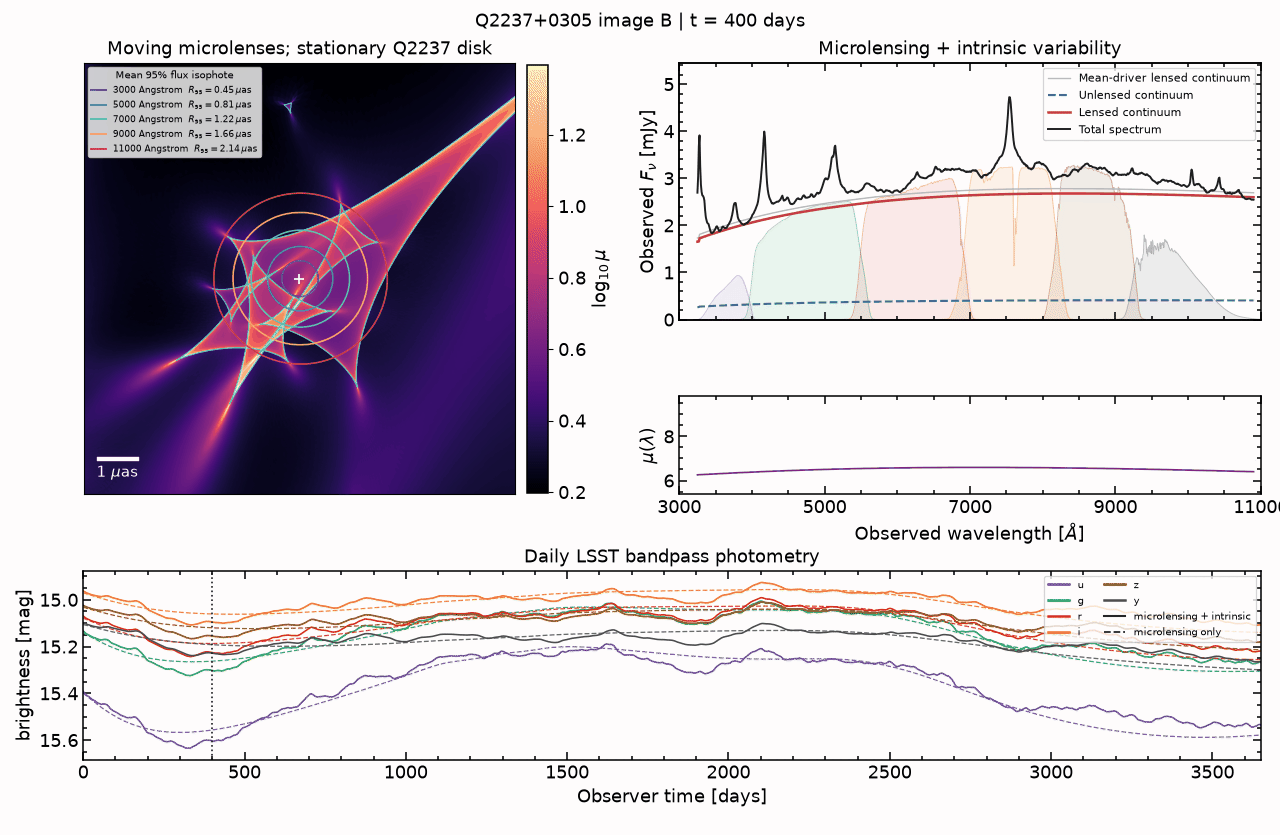

In [9]:
representative_frame = int(torch.argmin(
    torch.abs(map_times - float(crossing_times[0]))
))
lensed_gif = render_case(
    "q2237_realistic_spectrum", "Q2237+0305 image B",
    map_times, lensed_curve.times_days, lensed_curve.maps, spectra,
    lensed_curve, static_curve, caustics=captured_caustics,
)
from PIL import Image as PILImage
display(mcp.gif_preview(lensed_gif, start_frame=16, stop_frame=105))
print("Wrote", lensed_gif)


[View the full GIF](../assets/animations/q2237_realistic_spectrum_microlensing_and_variability.gif)

## Dataset guidance

For large training sets, pass one `QuasarSpectrum` per system to `batched_system_light_curves`, keep `return_spectrum=False`, and save only the six-band products. The fixed template tables are cached once per device and precision. Retain dense spectra only for systems that need spectral analysis or visualization. The broadband calculation still uses the full empirical spectrum when the dense output is not stored.
